# Estimación de parámetros y verificación de supuestos

Continuación del modelo de Silvia. Se conserva su forma de trabajo con pandas y statsmodels y la fórmula seleccionada.

In [1]:
import sys
import subprocess
if 'google.colab' in sys.modules:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'kagglehub', 'python-dotenv', 'statsmodels',
                           'pandas', 'numpy', 'scipy', 'matplotlib', 'scikit-learn'])


In [2]:
import os
from pathlib import Path
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from dotenv import load_dotenv
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
AZUL, NARANJA = '#2a78d6', '#eb6834'
pd.set_option('display.max_rows', 30)


## Acceso a Kaggle



In [ ]:
# Usar la configuración de Kaggle de cada integrante.
load_dotenv(Path.cwd() / ".env", override=False)
try:
    from google.colab import userdata
    token = userdata.get("KAGGLE_API_TOKEN")
    if token:
        os.environ["KAGGLE_API_TOKEN"] = token
except (ImportError, Exception):
    pass


## Carga de datos

Se utiliza la configuración de acceso a Kaggle de cada integrante.


In [4]:
data_dir = Path(kagglehub.competition_download('mae-competencia-regresion-202620'))
df_train = pd.read_csv(data_dir / 'Train real state.csv')
df_test = pd.read_csv(data_dir / 'Test real state.csv')
print('Entrenamiento:', df_train.shape)
print('Prueba:', df_test.shape)


100%|██████████| 68.6k/68.6k [00:00<00:00, 350kB/s]

Extracting files...
Entrenamiento: (4124, 31)
Prueba: (1767, 30)


## Preparación de las variables

Se mantienen los centrados y la regla de ventas en bloque usados por Silvia.

In [5]:
# Se conservan la limpieza y las transformaciones del modelo de Silvia.
train = df_train.copy()
test = df_test.copy()
for datos in [train, test]:
    datos['TimeToSubway'] = datos['TimeToSubway'].replace(
        {'0-5min': '0~5min', 'no_bus_stop_nearby': 'no_subway_nearby'})
    datos['Antiguedad'] = datos['YrSold'] - datos['YearBuilt']
    datos.columns = [c.rstrip('.').replace('.', '_') for c in datos.columns]
    datos['logSize_c'] = np.log(datos['Size_sqf'] / 910)
    datos['Antig_c'] = datos['Antiguedad'] - 10
    datos['YrSold_c'] = datos['YrSold'] - 2012
    datos['Parqueo_c'] = (datos['N_Parkinglot_Basement'] - 500) / 100
train['logPrice'] = np.log(train['SalePrice'])

llave_complejo = ['YearBuilt', 'SubwayStation', 'N_Parkinglot_Ground', 'N_Parkinglot_Basement']
claves = pd.concat([train[llave_complejo], test[llave_complejo]])
claves = claves.drop_duplicates().sort_values(llave_complejo).reset_index(drop=True)
claves['complejo'] = np.arange(len(claves))
train = train.merge(claves, on=llave_complejo, how='left', validate='many_to_one')
test = test.merge(claves, on=llave_complejo, how='left', validate='many_to_one')

ventas_mes = train.groupby(['complejo', 'YrSold', 'MonthSold']).size()
eventos = ventas_mes[ventas_mes >= 100].index
for datos in [train, test]:
    datos['Bloque'] = datos.set_index(['complejo', 'YrSold', 'MonthSold']).index.isin(eventos).astype(int)

print('Conjuntos:', train['complejo'].nunique())
print('Ventas en bloque:', train['Bloque'].sum())


Conjuntos: 26
Ventas en bloque: 291


## 1 Estimación de los parámetros

Los coeficientes se estiman por mínimos cuadrados ordinarios. Se comparan los errores estándar clásicos con los agrupados por conjunto, que se conservan para la inferencia. La tabla separa los coeficientes del cálculo de su incertidumbre.

In [6]:
formula_final = ('logPrice ~ logSize_c + I(logSize_c ** 2) + Floor + C(YrSold) '
                 '+ MonthSold + Bloque + Antig_c + I(Antig_c ** 2) '
                 '+ Antig_c:YrSold_c + Parqueo_c + logSize_c:Parqueo_c '
                 '+ N_SchoolNearBy_Total')

mco = smf.ols(formula_final, train).fit()
modelo_final = smf.ols(formula_final, train).fit(
    cov_type='cluster', cov_kwds={'groups': train['complejo']}, use_t=True)

tabla_parametros = pd.DataFrame({
    'Coeficiente': modelo_final.params,
    'EE clásico': mco.bse,
    'EE agrupado': modelo_final.bse
})
print('Ventas:', int(modelo_final.nobs))
print('Parámetros:', len(modelo_final.params))
print('Rango de la matriz:', np.linalg.matrix_rank(mco.model.exog))
print('Varianza residual clásica:', round(mco.mse_resid, 6))
display(tabla_parametros.round(5))


Ventas: 4124
Parámetros: 22
Rango de la matriz: 22
Varianza residual clásica: 0.016046


,Coeficiente,EE clásico,EE agrupado
Intercept,11.91598,0.01827,0.09318
C(YrSold)[T.2008],0.05583,0.01631,0.02767
C(YrSold)[T.2009],0.01061,0.01583,0.04411
C(YrSold)[T.2010],0.08510,0.01565,0.02940
C(YrSold)[T.2011],0.18105,0.01587,0.03176
C(YrSold)[T.2012],0.26038,0.01607,0.04600
C(YrSold)[T.2013],0.34052,0.01570,0.04896
C(YrSold)[T.2014],0.46564,0.01557,0.05457
C(YrSold)[T.2015],0.64357,0.01600,0.05511
C(YrSold)[T.2016],0.64582,0.01577,0.04796


## 2 Verificación de los supuestos

Se examinan los residuos del mismo modelo estimado. Las pruebas se acompañan con gráficos porque la agrupación por conjunto limita la lectura de los valores p clásicos.

### Forma funcional y varianza

En los gráficos se buscan curvaturas y cambios de dispersión. Breusch–Pagan contrasta varianza constante; su valor p se reporta como referencia nominal bajo los supuestos clásicos.

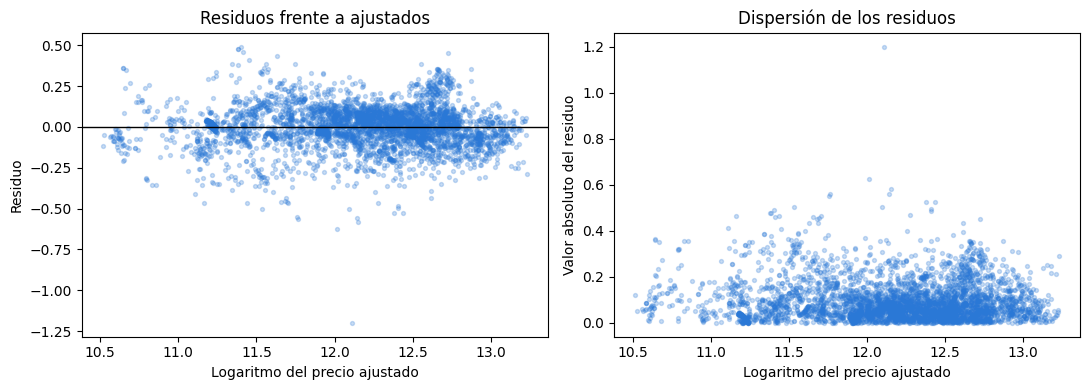

Breusch–Pagan: LM = 282.77, p nominal = 1.01e-47


In [7]:
residuos = mco.resid
ajustados = mco.fittedvalues
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(ajustados, residuos, s=8, alpha=0.25, color=AZUL)
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set(xlabel='Logaritmo del precio ajustado', ylabel='Residuo', title='Residuos frente a ajustados')
axes[1].scatter(ajustados, np.abs(residuos), s=8, alpha=0.25, color=AZUL)
axes[1].set(xlabel='Logaritmo del precio ajustado', ylabel='Valor absoluto del residuo', title='Dispersión de los residuos')
plt.tight_layout()
plt.show()

bp = het_breuschpagan(residuos, mco.model.exog)
print(f'Breusch–Pagan: LM = {bp[0]:.2f}, p nominal = {bp[1]:.3g}')


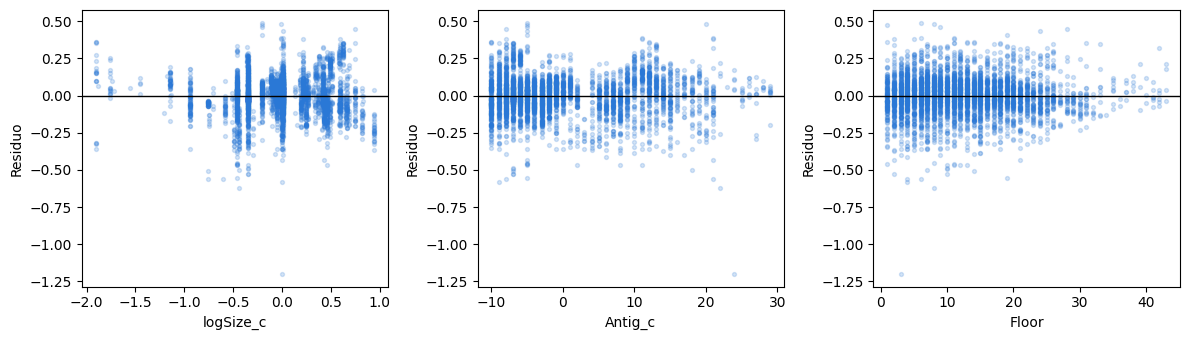

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, variable in zip(axes, ['logSize_c', 'Antig_c', 'Floor']):
    ax.scatter(train[variable], residuos, s=8, alpha=0.2, color=AZUL)
    ax.axhline(0, color='black', linewidth=1)
    ax.set(xlabel=variable, ylabel='Residuo')
plt.tight_layout()
plt.show()


### Normalidad

El histograma y el Q–Q muestran asimetría y colas. Jarque–Bera es complementario: con muchas ventas y dependencia dentro de conjuntos, no debe usarse como único criterio. La normalidad no es necesaria para calcular los coeficientes MCO.

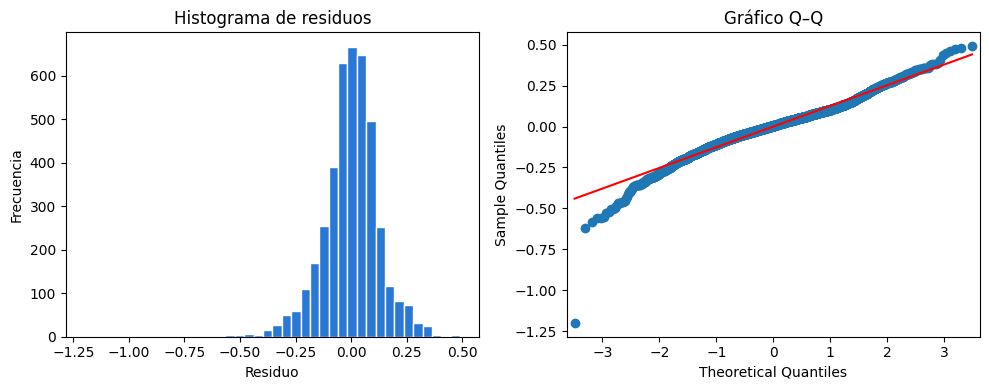

Jarque–Bera = 2253.63; p nominal = 0
Asimetría = -0.50
Exceso de curtosis = 3.48


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(residuos, bins=40, color=AZUL, edgecolor='white')
axes[0].set(xlabel='Residuo', ylabel='Frecuencia', title='Histograma de residuos')
sm.qqplot(residuos, line='s', ax=axes[1])
axes[1].set_title('Gráfico Q–Q')
plt.tight_layout()
plt.show()

jb = stats.jarque_bera(residuos)
print(f'Jarque–Bera = {jb.statistic:.2f}; p nominal = {jb.pvalue:.3g}')
print(f'Asimetría = {stats.skew(residuos):.2f}')
print(f'Exceso de curtosis = {stats.kurtosis(residuos):.2f}')


### Dependencia entre las observaciones

Las ventas comparten características dentro de cada conjunto. Se examinan sus residuos medios y el comportamiento temporal. El R² por conjunto es descriptivo; no es una correlación intraclase ni una prueba formal de independencia. Por eso se conserva la covarianza agrupada de Silvia. Con 26 conjuntos, la inferencia sigue siendo aproximada.

,size,mean,std
complejo,,,
0,51,0.0612,0.1354
1,3,-0.6119,0.5228
2,45,-0.2556,0.1161
3,212,0.0895,0.1167
4,54,-0.0793,0.0733
5,116,-0.0235,0.1291
6,206,-0.0507,0.1210
7,467,0.0272,0.1205
8,68,-0.2056,0.1137


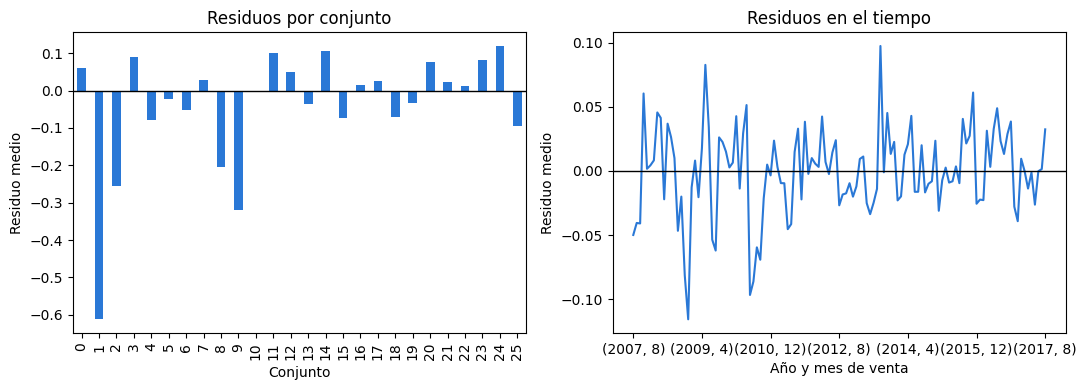

Variación residual asociada descriptivamente al conjunto: 29.2 %


In [10]:
revision = train[['id', 'complejo', 'YrSold', 'MonthSold']].copy()
revision['residuo'] = residuos.to_numpy()
por_conjunto = revision.groupby('complejo')['residuo'].agg(['size', 'mean', 'std'])
display(por_conjunto.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
por_conjunto['mean'].plot.bar(ax=axes[0], color=AZUL)
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set(xlabel='Conjunto', ylabel='Residuo medio', title='Residuos por conjunto')
por_mes = revision.groupby(['YrSold', 'MonthSold'])['residuo'].mean()
por_mes.plot(ax=axes[1], color=AZUL)
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set(xlabel='Año y mes de venta', ylabel='Residuo medio', title='Residuos en el tiempo')
plt.tight_layout()
plt.show()

r2_conjunto = smf.ols('residuo ~ C(complejo)', revision).fit().rsquared
print(f'Variación residual asociada descriptivamente al conjunto: {100*r2_conjunto:.1f} %')


### Observaciones que requieren revisión

Los residuos estandarizados, el apalancamiento y Cook señalan ventas a inspeccionar. Los umbrales no justifican eliminar registros automáticamente. Se conservan las ventas en bloque y los datos originales.

In [11]:
influencia = mco.get_influence()
revision['residuo_estandarizado'] = influencia.resid_studentized_internal
revision['apalancamiento'] = influencia.hat_matrix_diag
revision['Cook'] = influencia.cooks_distance[0]
n = int(mco.nobs)
p = len(mco.params)
revision['revisar'] = ((revision['residuo_estandarizado'].abs() > 3)
                       | (revision['apalancamiento'] > 2*p/n)
                       | (revision['Cook'] > 4/n))
print('Ventas señaladas para revisión:', int(revision['revisar'].sum()))
display(revision.loc[revision['revisar']].sort_values('Cook', ascending=False).head(15).round(4))


Ventas señaladas para revisión: 400


,id,complejo,YrSold,MonthSold,residuo,residuo_estandarizado,apalancamiento,Cook,revisar
2642,3798,1,2014,10,-1.2000,-9.5361,0.0131,0.0551,True
3978,5676,2,2017,7,-0.6229,-4.9419,0.0098,0.0110,True
224,324,0,2008,6,0.4790,3.8096,0.0149,0.0100,True
2510,3603,23,2014,7,0.3624,2.8982,0.0253,0.0099,True
3155,4522,23,2015,12,-0.3565,-2.8516,0.0258,0.0098,True
2509,3602,23,2014,7,0.3587,2.8685,0.0253,0.0097,True
2558,3665,23,2014,8,0.3511,2.8076,0.0255,0.0094,True
3649,5200,2,2016,11,-0.5609,-4.4494,0.0098,0.0089,True
3153,4520,19,2015,12,-0.5589,-4.4321,0.0089,0.0081,True
3044,4349,23,2015,7,-0.3231,-2.5829,0.0247,0.0077,True


### Síntesis

Los errores agrupados ajustan la incertidumbre, pero no corrigen por sí solos una media mal especificada. La media de los residuos cercana a cero no demuestra exogeneidad. Los VIF y el centrado ya fueron tratados en el apartado de estructura del modelo de Silvia.

In [12]:
sintesis = pd.DataFrame({
    'Aspecto': ['Identificación', 'Varianza constante', 'Normalidad marginal', 'Agrupación', 'Influencia'],
    'Resultado': [
        f"Rango {np.linalg.matrix_rank(mco.model.exog)} de {len(mco.params)} columnas",
        f'Breusch–Pagan: LM={bp[0]:.2f}; p nominal={bp[1]:.3g}',
        f'Jarque–Bera={jb.statistic:.2f}; p nominal={jb.pvalue:.3g}',
        f"{train['complejo'].nunique()} conjuntos; R² descriptivo={r2_conjunto:.3f}",
        f"{int(revision['revisar'].sum())} ventas señaladas"
    ]
})
display(sintesis)

tabla_parametros.to_csv('Parametros_Andres.csv', encoding='utf-8-sig')
sintesis.to_csv('Diagnostico_Andres.csv', index=False, encoding='utf-8-sig')
revision.loc[revision['revisar']].to_csv('Ventas_a_revisar.csv', index=False)


,Aspecto,Resultado
0,Identificación,Rango 22 de 22 columnas
1,Varianza constante,Breusch–Pagan: LM=282.77; p nominal=1.01e-47
2,Normalidad marginal,Jarque–Bera=2253.63; p nominal=0
3,Agrupación,26 conjuntos; R² descriptivo=0.292
4,Influencia,400 ventas señaladas


## Revisión de sensibilidad

Se inspecciona la venta 3798 y se comparan dos exclusiones concretas. El modelo principal no se modifica.


In [13]:
# Revisión del caso con mayor residuo y sensibilidad del ajuste
caso = train.loc[train['id'] == 3798]
columnas = ['id','SalePrice','YearBuilt','YrSold','MonthSold','Size_sqf','Floor','SubwayStation','N_Parkinglot_Ground','N_Parkinglot_Basement','complejo']
display(caso[columnas])
referencia = caso.iloc[0]
vecinos = train.loc[(train['SubwayStation'] == referencia['SubwayStation']) & (train['N_Parkinglot_Ground'] == referencia['N_Parkinglot_Ground']) & (train['N_Parkinglot_Basement'] == referencia['N_Parkinglot_Basement'])]
display(vecinos.groupby(['YearBuilt','complejo']).agg(Ventas=('id','size'), Precio_medio=('SalePrice','mean')))
sin_caso = smf.ols(formula_final, train.loc[train['id'] != 3798]).fit()
sin_conjunto = smf.ols(formula_final, train.loc[train['complejo'] != referencia['complejo']]).fit()
sensibilidad = pd.DataFrame({'Modelo completo': mco.params, 'Sin venta 3798': sin_caso.params, 'Sin conjunto del caso': sin_conjunto.params, 'EE agrupado completo': modelo_final.bse})
sensibilidad['Cambio sin venta / EE'] = (sensibilidad['Sin venta 3798'] - sensibilidad['Modelo completo']) / sensibilidad['EE agrupado completo']
sensibilidad['Cambio sin conjunto / EE'] = (sensibilidad['Sin conjunto del caso'] - sensibilidad['Modelo completo']) / sensibilidad['EE agrupado completo']
display(sensibilidad.round(5))
print('Rangos de las matrices de sensibilidad:', np.linalg.matrix_rank(sin_caso.model.exog), np.linalg.matrix_rank(sin_conjunto.model.exog))
print('Máximo Cook:', round(revision['Cook'].max(), 5))
sensibilidad.to_csv('Sensibilidad_Andres.csv', encoding='utf-8-sig')


Rangos de las matrices de sensibilidad: 22 22
Máximo Cook: 0.05507


# Estimación de parámetros y verificación de supuestos

## Estimación de parámetros

Se mantuvo la estructura del modelo seleccionada previamente y se estimaron sus parámetros por mínimos cuadrados ordinarios. La respuesta es el logaritmo natural del precio de venta. La especificación incluye el tamaño, el piso, el momento de la venta, las ventas en bloque, la antigüedad, los parqueaderos en sótano y las escuelas cercanas, junto con los términos cuadrados e interacciones definidos en el apartado de estructura.

El ajuste utiliza 4.124 ventas y 22 parámetros, incluido el intercepto. La matriz de diseño tiene rango 22, por lo que los coeficientes están identificados. La varianza residual clásica estimada es 0,016046 en escala logarítmica. Se conservaron los centrados: logaritmo del tamaño respecto de 910 pies cuadrados, antigüedad respecto de diez años, año de venta respecto de 2012 para la interacción y parqueaderos en centenas respecto de 500. El año de referencia de las indicadoras es 2007.

Los errores estándar se calcularon agrupando las ventas por los 26 conjuntos residenciales. Esta decisión permite heterocedasticidad y dependencia dentro de cada conjunto y no modifica los coeficientes MCO. Se emplea la corrección finita de la covarianza agrupada de statsmodels y la referencia t con 25 grados de libertad. La inferencia supone independencia entre conjuntos y sigue siendo aproximada con este número de grupos. Los intervalos y contrastes posteriores deben conservar esta misma covarianza.

## Verificación de los supuestos

### Forma funcional y varianza

Los residuos se concentran alrededor de cero, pero su dispersión cambia a lo largo de los valores ajustados. Los gráficos frente al tamaño y la antigüedad muestran agrupamientos y diferencias en la posición y amplitud de los residuos. No constituyen evidencia suficiente para declarar completamente resuelta la estructura de la media. Las bandas verticales también reflejan valores repetidos de las explicativas.

Breusch–Pagan produce LM = 282,77 y p nominal = 1,01 × 10⁻⁴⁷, resultado contrario a la hipótesis de varianza constante. Su referencia clásica requiere cautela por la agrupación de las ventas, pero el contraste y la dispersión observada aconsejan no emplear errores estándar homocedásticos. Se mantiene la covarianza agrupada; esta elección ajusta la incertidumbre y no corrige por sí sola una media mal especificada ni atributos omitidos.

### Normalidad

El histograma presenta una concentración marcada cerca de cero. El gráfico Q–Q se aparta de la recta de referencia en ambas colas, especialmente en la inferior. La asimetría es −0,50 y el exceso de curtosis 3,48. Jarque–Bera arroja 2.253,63, con un valor p nominal inferior a la precisión mostrada por el programa. El cero de la salida no se interpreta como una probabilidad exactamente nula.

Los resultados muestran desviaciones de normalidad marginal. La prueba no se usa de forma aislada ni como contraste ajustado por conglomerados. La normalidad no es necesaria para calcular MCO, aunque sí interviene en la inferencia clásica exacta; en este análisis se conserva la inferencia robusta agrupada y se reconocen sus límites con 26 conjuntos.

### Dependencia y diferencias entre conjuntos

Persisten diferencias entre los residuos medios de los conjuntos. Las indicadoras de conjunto explican descriptivamente el 29,2 % de la variación residual. Este porcentaje no es una correlación intraclase ni una prueba formal de independencia. El gráfico mensual muestra oscilaciones alrededor de cero que, por sí solas, tampoco establecen autocorrelación.

La estructura de las ventas y los patrones residuales justifican considerar la agrupación. Se mantiene la covarianza por conjunto sin afirmar que la independencia entre conjuntos haya quedado demostrada. La media residual cercana a cero, consecuencia del ajuste con intercepto, no demuestra que el error tenga esperanza condicional cero. Los coeficientes se interpretan como asociaciones condicionadas a las variables incluidas, con posible confusión por atributos no observados.

### Influencia y sensibilidad

Se señalaron 400 ventas, aproximadamente el 9,7 % de la muestra, mediante al menos uno de los umbrales exploratorios: residuo estandarizado absoluto mayor que tres, apalancamiento superior a 2p/n o distancia de Cook superior a 4/n. Las alertas no se consideran errores de registro ni criterios automáticos de eliminación.

La venta 3798 presenta precio de USD 54.867, tamaño de 910 pies cuadrados, piso 3, año de construcción 1980 y venta en octubre de 2014. Tiene residuo estandarizado −9,54 y Cook 0,05507, el máximo observado. Sus datos de estación y parqueaderos coinciden con registros identificados como construidos en 2014. La coincidencia merece revisión en la fuente, pero no permite corregir el año ni identificar automáticamente ambas agrupaciones como un mismo edificio.

Se comparó el ajuste completo con dos variantes de sensibilidad, sin modificar el modelo principal. Al retirar solo la venta 3798, el mayor cambio de los coeficientes equivale a 0,130 errores estándar agrupados del modelo completo; al retirar las tres ventas de su conjunto, a 0,192. Ambas matrices conservan rango 22. El resultado indica estabilidad de los coeficientes frente a estas exclusiones concretas, sin descartar otros posibles problemas de influencia. Se conserva la muestra completa.

## Decisión para continuar

Se mantienen la fórmula logarítmica, las 4.124 ventas y la covarianza agrupada por conjunto. Se reportan heterocedasticidad, desviaciones de normalidad y patrones residuales entre conjuntos; no se declara que todos los supuestos estén satisfechos. Los apartados siguientes deben usar los objetos `modelo_final`, `formula_final` y `train` para mantener coherencia en bondad de ajuste, intervalos, pruebas e interpretación. El modelo del informe se distingue de la variante predictiva de Kaggle con efectos fijos y Box–Cox.


In [14]:
# Comprobación de los resultados del modelo
assert len(train) == 4124
assert train['complejo'].nunique() == 26
assert len(modelo_final.params) == np.linalg.matrix_rank(mco.model.exog) == 22
assert np.isclose(modelo_final.params['logSize_c'], 0.80866, atol=0.00001)
assert int(revision['revisar'].sum()) == 400
print('VERIFICACIÓN CORRECTA: 4124 ventas, 26 conjuntos, 22 parámetros y rango completo.')
print('Modelo reproducido desde una sesión nueva. Se conservan todas las ventas.')
print('Cambio máximo sin venta 3798 / EE:', round(sensibilidad['Cambio sin venta / EE'].abs().max(), 5))
print('Cambio máximo sin conjunto / EE:', round(sensibilidad['Cambio sin conjunto / EE'].abs().max(), 5))


VERIFICACIÓN CORRECTA: 4124 ventas, 26 conjuntos, 22 parámetros y rango completo.
Modelo reproducido desde una sesión nueva. Se conservan todas las ventas.
Cambio máximo sin venta 3798 / EE: 0.12981
Cambio máximo sin conjunto / EE: 0.19241
